# Cleaning and Hessian curvature classes

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy import ndimage
import seafloor as sf

lon, lat, z_raw = sf.load()
_, _, zm = sf.load(layer="topo-mask")
ship = ~np.isnan(zm)
dx, dy = sf.cell_size_m(lon, lat); DX = float(dx.mean())
LON, LAT = np.meshgrid(lon, lat)
extent = [lon[0], lon[-1], lat[0], lat[-1]]; aspect = 1 / np.cos(np.deg2rad(lat.mean()))

def slope_deg(z):
    gy, gx = np.gradient(z, dy, axis=0), np.gradient(z, axis=1) / dx[:, None]
    return np.degrees(np.arctan(np.hypot(gx, gy)))
print(f"Grid {z_raw.shape}, cell ≈ {DX:.0f} m")

Grid (1365, 1824), cell ≈ 478 m


In [2]:
S_raw = slope_deg(z_raw)
ii, jj = np.nonzero(S_raw > 55)
print(f"Cells steeper than 55°: {ii.size}   (ship-measured: {ship[ii, jj].sum()})")
spots = {}
for a, b in zip(ii, jj):
    spots.setdefault((round(lat[a], 1), round(lon[b], 1)), []).append((a, b))
for (la, lo), cells in sorted(spots.items(), key=lambda kv: -len(kv[1])):
    a, b = cells[0]
    print(f"  near {la:5.1f}°N {lo:6.1f}°E: {len(cells):2d} cells, e.g. depth {z_raw[a, b]:>7,.0f} m, neighbours",
          z_raw[a-1:a+2, b-1:b+2].round(-1).astype(int).tolist())

Cells steeper than 55°: 75   (ship-measured: 0)
  near  13.4°N  144.7°E: 58 cells, e.g. depth     270 m, neighbours [[40, 170, 220], [30, 270, 210], [30, -1480, 280]]
  near  13.5°N  144.7°E: 11 cells, e.g. depth     -34 m, neighbours [[-40, -20, -2340], [-20, -30, -2430], [-20, -1250, -2240]]
  near   9.1°N  141.3°E:  3 cells, e.g. depth  -1,981 m, neighbours [[-1350, -1310, -1250], [-1530, -1980, -2140], [-2150, -2800, -2980]]
  near  12.3°N  147.5°E:  2 cells, e.g. depth  -2,718 m, neighbours [[-1970, -2500, -3190], [-2090, -2720, -3740], [-2490, -3020, -3760]]
  near   9.4°N  140.4°E:  1 cells, e.g. depth  -2,943 m, neighbours [[-3400, -3020, -2150], [-3410, -2940, -2180], [-2250, -2270, -2320]]


In [3]:
resid = z_raw - ndimage.median_filter(z_raw, size=5)
print(f"Typical |residual| (median): {np.median(np.abs(resid)):.1f} m;  99.9th percentile: {np.percentile(np.abs(resid), 99.9):.0f} m")

spike = np.abs(resid) > 500
land = z_raw >= 0
coast = ndimage.binary_dilation(land, iterations=2) & ~land
bad = spike | land | coast

z = z_raw.copy(); z[bad] = np.nan
print(f"Removed: {spike.sum()} spikes, {land.sum()} land cells, {coast.sum()} coastal cells "
      f"({bad.mean():.2%} of grid)")

S = slope_deg(z)
print(f"Max slope before cleaning: {np.nanmax(S_raw):.1f}°   after: {np.nanmax(S):.1f}°")
st = S > 45
print(f"Cells steeper than 45° after cleaning: {st.sum()}  (ship-measured: {(st & ship).sum()})")
print(f"99.9th pct slope before: {np.nanpercentile(S_raw, 99.9):.1f}°   after: {np.nanpercentile(S, 99.9):.1f}°")
np.save(sf.DATA_DIR / "z_clean.npy", z)

Typical |residual| (median): 3.8 m;  99.9th percentile: 198 m
Removed: 48 spikes, 3125 land cells, 1262 coastal cells (0.18% of grid)
Max slope before cleaning: 75.6°   after: 61.1°
Cells steeper than 45° after cleaning: 53  (ship-measured: 8)
99.9th pct slope before: 31.8°   after: 31.5°


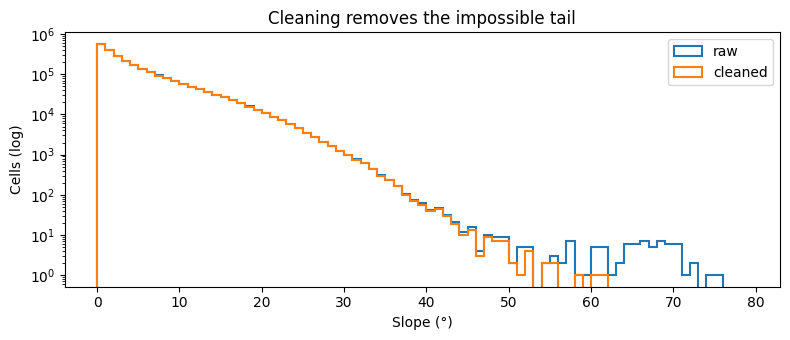

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.5))
bins = np.arange(0, 80, 1)
ax.hist(S_raw[~np.isnan(S_raw)], bins, histtype="step", lw=1.5, label="raw")
ax.hist(S[~np.isnan(S)], bins, histtype="step", lw=1.5, label="cleaned")
ax.set(yscale="log", xlabel="Slope (°)", ylabel="Cells (log)", title="Cleaning removes the impossible tail")
ax.legend(); fig.tight_layout(); fig.savefig(sf.FIG_DIR / "03_cleaning.png", dpi=200); plt.show()

high      cell ≈    61 m   Challenger Deep = -10,940 m
max       cell ≈    61 m   Challenger Deep = -10,940 m
med       cell ≈   121 m   Challenger Deep = -10,940 m
low       cell ≈   243 m   Challenger Deep = -10,934 m
main grid cell ≈   478 m   Challenger Deep = -10,639 m


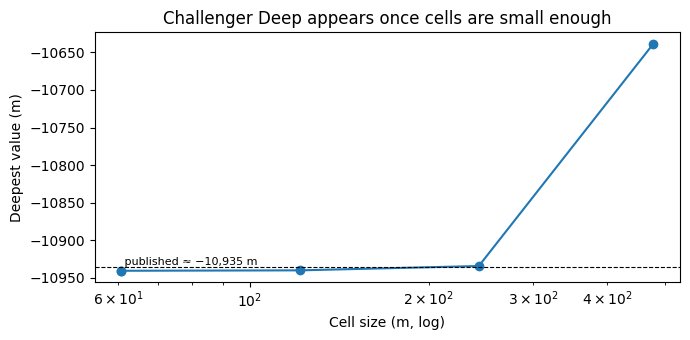

In [5]:
KNOWN_CD = (11.37, 142.59)
near = sf.distance_km(LAT, LON, *KNOWN_CD) < 20
pts = [(DX, np.nanmin(np.where(near, z_raw, np.nan)), "main grid")]
CD_BOX = dict(west=141.9, east=143.0, south=11.1, north=11.6)
for res in ["low", "med", "high", "max"]:
    try:
        lo_, la_, zz = sf.load(CD_BOX, res)
        pts.append((sf.cell_size_m(lo_, la_)[1], np.nanmin(zz), res))
    except Exception as e:
        print(res, "unavailable:", e)
pts.sort()
for c, d, name in pts: print(f"{name:9s} cell ≈ {c:5.0f} m   Challenger Deep = {d:,.0f} m")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot([p[0] for p in pts], [p[1] for p in pts], "o-")
ax.axhline(-10935, ls="--", c="k", lw=0.8); ax.text(pts[0][0], -10935, " published ≈ −10,935 m", va="bottom", fontsize=8)
ax.set(xscale="log", xlabel="Cell size (m, log)", ylabel="Deepest value (m)", title="Challenger Deep appears once cells are small enough")
fig.tight_layout(); fig.savefig(sf.FIG_DIR / "03_resolution_depth.png", dpi=200); plt.show()

In [6]:
def hessian_eigs(z, sigma_m):
    zf = np.where(np.isnan(z), np.nanmedian(z), z)
    zs = ndimage.gaussian_filter(zf, sigma_m / DX)
    zy, zx = np.gradient(zs, dy, DX)
    zyy, zyx = np.gradient(zy, dy, DX)
    zxy, zxx = np.gradient(zx, dy, DX)
    return eig_sym2(zxx, zyy, 0.5 * (zxy + zyx))

def eig_sym2(a, d, b):
    mean = 0.5 * (a + d)
    rad = np.sqrt((0.5 * (a - d)) ** 2 + b ** 2)
    return mean - rad, mean + rad

rng = np.random.default_rng(0)
a_, d_, b_ = rng.normal(size=(3, 1000))
mine = np.stack(eig_sym2(a_, d_, b_), axis=1)
ref = np.linalg.eigvalsh(np.stack([np.stack([a_, b_], -1), np.stack([b_, d_], -1)], 1))
print(f"Closed form vs numpy, max difference: {np.abs(mine - ref).max():.1e}")

l1, l2 = hessian_eigs(z, 2000)

CLASSES = ["planar", "peak", "pit", "ridge", "valley", "saddle"]
COLORS  = ["#d9d9d9", "#d62728", "#1f77b4", "#ff7f0e", "#17becf", "#9467bd"]

def classify(l1, l2, t=1e-5):
    c = np.zeros(l1.shape, dtype=np.int8)
    c[(l1 < -t) & (l2 < -t)] = 1
    c[(l1 >  t) & (l2 >  t)] = 2
    c[(l1 < -t) & (np.abs(l2) <= t)] = 3
    c[(np.abs(l1) <= t) & (l2 > t)] = 4
    c[(l1 < -t) & (l2 > t)] = 5
    return c

Closed form vs numpy, max difference: 8.9e-16


In [7]:
xx, yy = np.meshgrid(np.arange(-40, 41) * DX, np.arange(-40, 41) * dy)
hill = -5000 + 2000 * np.exp(-(xx**2 + yy**2) / (2 * 6000**2))
ha, hb = hessian_eigs(hill, 1000)
hc = classify(ha, hb)
print("Centre of test hill classified as:", CLASSES[hc[40, 40]], "| far away:", CLASSES[hc[0, 0]])

Centre of test hill classified as: peak | far away: planar


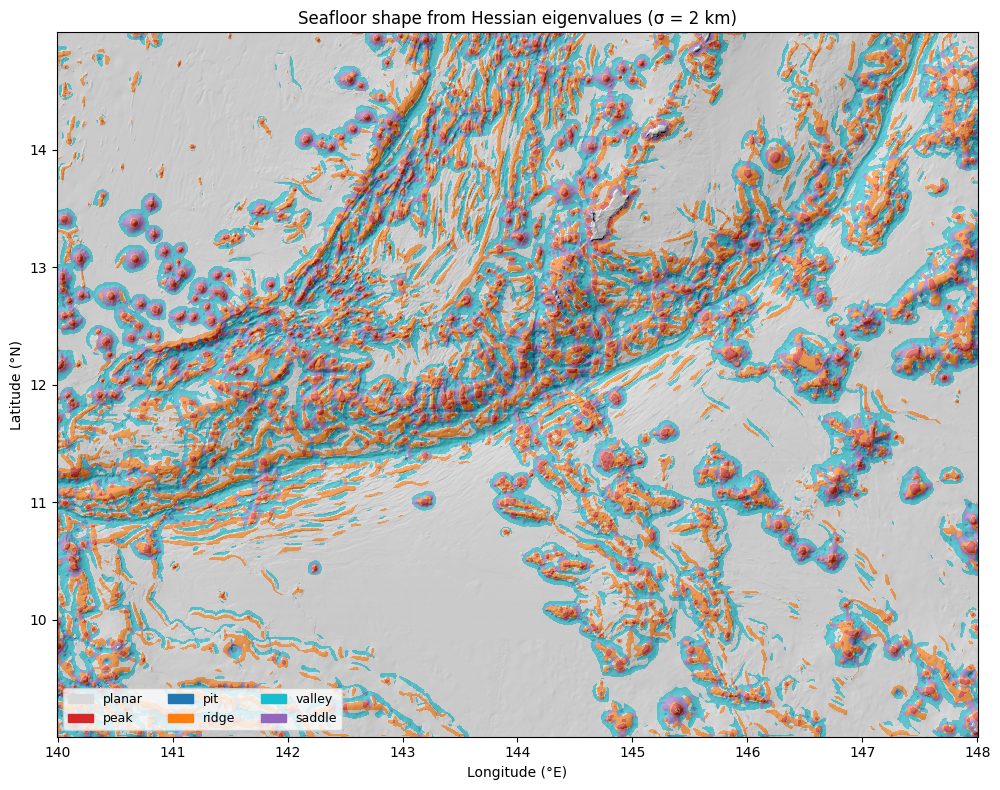

Share of seafloor area by shape:
  planar   52.2%   ship-measured:  49.4%   satellite-only:  56.4%
  peak      3.1%   ship-measured:   3.2%   satellite-only:   2.9%
  pit       1.5%   ship-measured:   1.7%   satellite-only:   1.2%
  ridge    15.3%   ship-measured:  15.8%   satellite-only:  14.7%
  valley   20.4%   ship-measured:  21.7%   satellite-only:  18.4%


  saddle    7.4%   ship-measured:   8.2%   satellite-only:   6.3%


In [8]:
cls = classify(l1, l2)
cls_plot = np.where(np.isnan(z), -1, cls).astype(float); cls_plot[cls_plot < 0] = np.nan
shade = sf.hillshade(z_raw, dx, dy)

fig, ax = plt.subplots(figsize=(11, 8))
ax.imshow(shade, extent=extent, origin="lower", cmap="gray", aspect=aspect)
ax.imshow(cls_plot, extent=extent, origin="lower", cmap=ListedColormap(COLORS), vmin=-0.5, vmax=5.5,
          alpha=0.6, aspect=aspect, interpolation="nearest")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in COLORS]
ax.legend(handles, CLASSES, loc="lower left", ncol=3, fontsize=9)
ax.set(xlabel="Longitude (°E)", ylabel="Latitude (°N)", title="Seafloor shape from Hessian eigenvalues (σ = 2 km)")
fig.tight_layout(); fig.savefig(sf.FIG_DIR / "03_shape_classes.png", dpi=200); plt.show()

w = np.cos(np.deg2rad(LAT)); ok = ~np.isnan(z)
print("Share of seafloor area by shape:")
for k, name in enumerate(CLASSES):
    m = ok & (cls == k)
    print(f"  {name:7s} {(w * m).sum() / (w * ok).sum():6.1%}   ship-measured: {(w*(m & ship)).sum()/(w*(ok & ship)).sum():6.1%}"
          f"   satellite-only: {(w*(m & ~ship)).sum()/(w*(ok & ~ship)).sum():6.1%}")

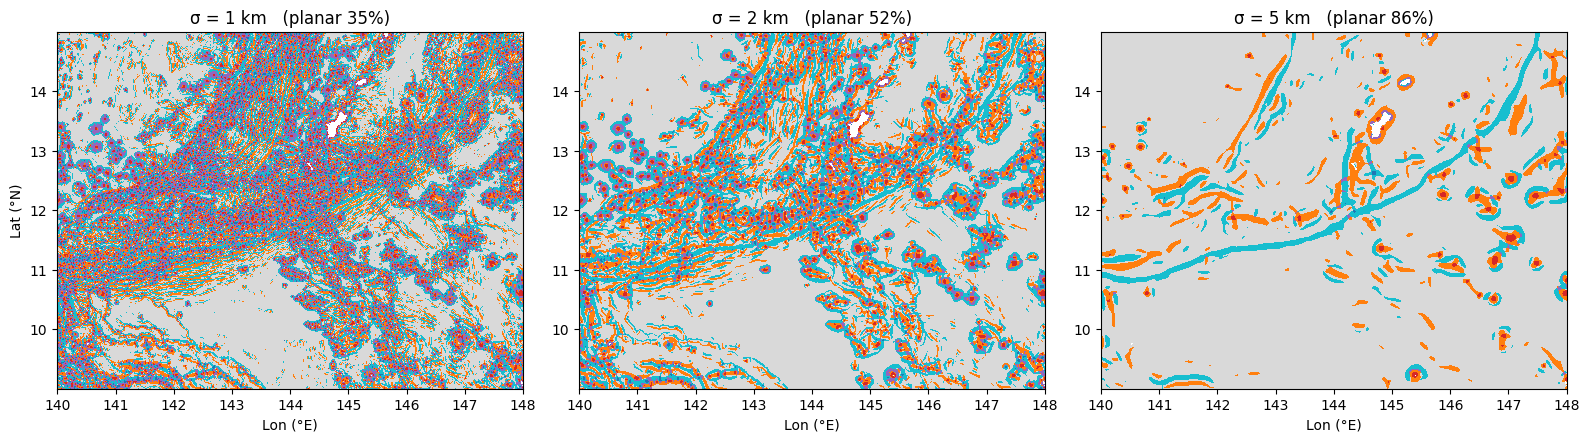

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
share = {}
for ax, s in zip(axes, [1000, 2000, 5000]):
    a, b = hessian_eigs(z, s); c = classify(a, b)
    share[s] = [(c[ok] == k).mean() for k in range(6)]
    cp = np.where(ok, c, np.nan)
    ax.imshow(cp, extent=extent, origin="lower", cmap=ListedColormap(COLORS), vmin=-0.5, vmax=5.5, aspect=aspect, interpolation="nearest")
    ax.set(title=f"σ = {s/1000:.0f} km   (planar {share[s][0]:.0%})", xlabel="Lon (°E)")
axes[0].set_ylabel("Lat (°N)")
fig.tight_layout(); fig.savefig(sf.FIG_DIR / "03_sigma.png", dpi=150); plt.show()

In [10]:
print("KEY NUMBERS")
print(f"  Cleaned: {spike.sum()} spikes, {land.sum()} land, {coast.sum()} coastal cells; max slope {np.nanmax(S_raw):.0f}° → {np.nanmax(S):.0f}°")
for c_, d, name in pts: print(f"  Challenger Deep, {name} (~{c_:.0f} m cells): {d:,.0f} m")
for k, name in enumerate(CLASSES):
    print(f"  {name:7s} σ=1km {share[1000][k]:5.1%} | σ=2km {share[2000][k]:5.1%} | σ=5km {share[5000][k]:5.1%}")

KEY NUMBERS
  Cleaned: 48 spikes, 3125 land, 1262 coastal cells; max slope 76° → 61°
  Challenger Deep, high (~61 m cells): -10,940 m
  Challenger Deep, max (~61 m cells): -10,940 m
  Challenger Deep, med (~121 m cells): -10,940 m
  Challenger Deep, low (~243 m cells): -10,934 m
  Challenger Deep, main grid (~478 m cells): -10,639 m
  planar  σ=1km 34.7% | σ=2km 52.2% | σ=5km 85.7%
  peak    σ=1km  5.5% | σ=2km  3.1% | σ=5km  0.5%
  pit     σ=1km  4.6% | σ=2km  1.5% | σ=5km  0.0%
  ridge   σ=1km 16.5% | σ=2km 15.3% | σ=5km  6.8%
  valley  σ=1km 22.1% | σ=2km 20.4% | σ=5km  6.6%
  saddle  σ=1km 16.5% | σ=2km  7.4% | σ=5km  0.3%
